---
**UNIVERSIDAD NACIONAL DE ASUNCIÓN**

**FACULTAD DE INGENIERÍA**

# **ROBÓTICA II**

TRABAJO PRÁCTICO FINAL 2026S2

## **"Robot recolector de Limones"**


---
###**ROBOT:** [Arturito R2D2]

**Grupo [2]:**


*   Pablo Junior Otazu Lujan
*   Pedro Daniel Vera Ramírez
*   Héctor Dejesús Velázquez Ojeda
*   Mathias Ramón Aguilar Delvalle

**ENTREGA [4]:** Actuadores y cálculo de autonomía.


**Fecha:** [04/10/2026]

**Versión:** [1.0]

---

## Introducción

En esta entrega se documenta la selección de los actuadores del robot, su montaje en el prototipo y la forma en que se controlan, y se calcula la autonomía a partir del consumo de cada subsistema. Con ese cálculo se corrige el diseño para incluir las baterías.

La consigna menciona actuadores de corte y *trimming*, que corresponden a la opción A (cortador de chupones). Nuestro robot es de la opción B (recolector): su actuador de trabajo es un **brazo RRR con una pinza de agarre, tracción y giro**, que reemplaza a la succión con aprobación del profesor. Por eso se documentan los actuadores del brazo (J1, J2 y J3), los de la pinza y los de la tracción de la base.

## Etapa 1: Selección de actuadores

### 1.1 Requerimientos

| Subsistema | Tarea | Requerimiento |
|---|---|---|
| Tracción | Recorrer la hilera y frenar frente a cada árbol | 0,25 m/s en terreno de huerto, robot de ~8 kg (la guía pide ≥ 5 kg) |
| Brazo (J1-J3) | Llevar la pinza hasta el limón, a 0,40-0,95 m de las cámaras | Sostener su propio peso y el del limón con la herramienta horizontal |
| Pinza | Sujetar el limón, girarlo y desprenderlo | Fuerza de agarre sin dañar la fruta; giro sobre el eje de la herramienta |

Los motores trabajan a 12 V y se manejan con drivers IBT-2 (BTS7960) [2], que aceptan hasta 43 A por puente. Se descartó el L298N (2 A por canal) porque la corriente con el rotor trabado de cualquiera de estos motores es de 10 A.

### 1.2 Tracción: 42GM-895H planetario

Para la fuerza necesaria se toma el caso desfavorable: robot de 8 kg, resistencia a la rodadura en suelo de huerto $C_{rr} = 0{,}1$, una pendiente de 5° y la aceleración de la rampa del firmware ($a = 0{,}3$ m/s²):

$$F = m\,g\,(C_{rr}\cos\theta + \sin\theta) + m\,a = 8 \cdot 9{,}81\,(0{,}1 \cdot 0{,}996 + 0{,}087) + 8 \cdot 0{,}3 \approx 17{,}1\ \text{N}$$

Con dos ruedas motrices de radio $r = 0{,}075$ m, cada una debe dar

$$\tau_{rueda} = \frac{F}{2}\,r = 8{,}6 \cdot 0{,}075 \approx 0{,}64\ \text{N·m} \approx 6{,}5\ \text{kgf·cm}$$

y para 0,25 m/s la rueda gira a $\omega = v/r = 3{,}3$ rad/s ≈ **32 rpm**.

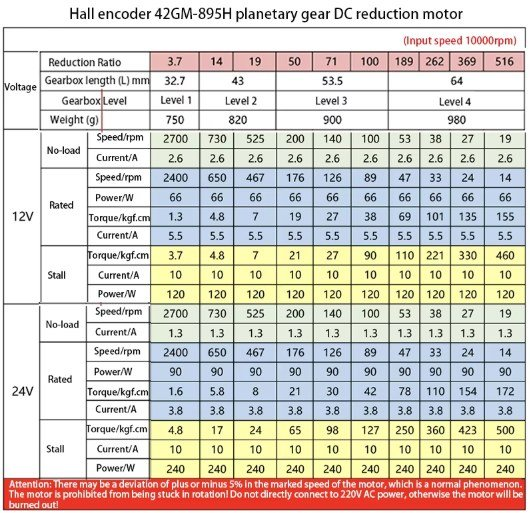

<div align="center"><b>Figura 1.</b> Tabla del vendedor del 42GM-895H. Se eligió la reducción 189:1 (columna de 53 rpm) a 12 V.</div>

El 42GM-895H con reducción 189:1 da 47 rpm y **69 kgf·cm nominales** (110 kgf·cm con el rotor trabado) a 12 V: más de 10 veces el par calculado y con velocidad de sobra (47 rpm equivalen a 0,37 m/s). El margen grande cubre el arranque desde parado, los pozos y la incertidumbre de la masa final. El encoder Hall de 11 PPR da 8316 cuentas por vuelta de la rueda (11 × 4 × 189), suficiente para la odometría.

### 1.3 Brazo: J1, J2 y J3

El brazo es de tipo uArm / Dobot Magician: un cuatro barras y un paralelogramo mantienen la herramienta siempre horizontal. Los motores de J2 y J3 están en la base del brazo, así que no suman momento sobre los eslabones. Medidas de la Entrega 4 de Robótica I: $L_2 = 0{,}350$ m y $L_3 = 0{,}330$ m.

**Par en J2 (hombro), caso más desfavorable:** brazo extendido en horizontal, con masas estimadas (a medir en el robot) de 0,15 kg por eslabón, 0,22 kg de pinza con sus dos servos y 0,15 kg de limón:

$$\tau_{J2} = g\left[m_{L2}\frac{L_2}{2} + m_{L3}\left(L_2 + \frac{L_3}{2}\right) + (m_p + m_l)(L_2 + L_3)\right] \approx 9{,}81 \cdot 0{,}355 \approx 3{,}5\ \text{N·m} \approx 35\ \text{kgf·cm}$$

**Par en J3 (codo):** $\tau_{J3} = g\,[m_{L3}\,L_3/2 + (m_p + m_l)\,L_3] \approx 1{,}4$ N·m ≈ **15 kgf·cm**.

**Par en J1 (giro de la base):** no levanta peso; lo domina la inercia. Con $I \approx \sum m\,r^2 \approx 0{,}22$ kg·m² y la aceleración máxima del firmware (60 °/s² = 1,05 rad/s²), $\tau_{J1} \approx 0{,}23$ N·m ≈ 2,3 kgf·cm más la fricción.

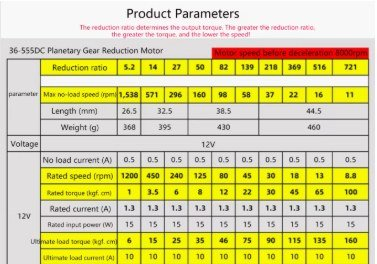

<div align="center"><b>Figura 2.</b> Tabla del vendedor del 36-555 a 12 V. J1 usa la reducción 50:1 (160 rpm); J2 y J3, la 139:1 (58 rpm).</div>

| Articulación | Motor | Par nominal del motor | Transmisión | Par en la articulación (η ≈ 0,9) | Necesario | Margen |
|---|---|---|---|---|---|---|
| J1 | 36GP-555, 160 rpm (50:1) | 8 kgf·cm | correa 18 → 90 (5:1) | 36 kgf·cm | ~2,3 kgf·cm + fricción | > 10 |
| J2 | 36-555, 58 rpm (139:1) | 22 kgf·cm | correa GT2 20 → 100 (5:1) | 99 kgf·cm | 35 kgf·cm | 2,8 |
| J3 | 36-555, 58 rpm (139:1) | 22 kgf·cm | correa GT2 20 → 100 (5:1) | 99 kgf·cm | 15 kgf·cm | 6,6 |

**Historia de la selección.** J2 y J3 empezaron con motores de sin fin 5840: J2 no levantaba el brazo y J3 tambaleaba por el juego del sin fin. Se cambiaron por el 36-555 con correa 5:1; primero se eligió el de 98 rpm (12 kgf·cm, margen de 1,5 en J2) y después el de **58 rpm** (22 kgf·cm), que da margen para el limón y para errores en las masas. La velocidad de la articulación queda en 58 / 5 ≈ 11,6 rpm (70 °/s), suficiente para la tarea. Como los planetarios no se autobloquean, sin corriente el brazo cae: el reposo queda apoyado en un tope.

En J1 se había comprado por error un motor de 2700 rpm; se reemplazó por el 36GP-555 de 160 rpm, caracterizado en la Entrega 5 de Robótica I. Los tres motores traen el encoder SCX-555 (16 PPR, 64 cuentas por vuelta del motor).

### 1.4 Pinza: 2 servos DSSERVO RDS3218

La pinza tiene dos servos digitales de 20 kg·cm (4,8-6,8 V): uno abre y cierra los dedos y el otro gira la herramienta sobre su eje (J4), para desprender el limón con tracción y giro, como en los efectores de agarre para cítricos revisados en [3]. Con dedos de ~5 cm (a medir), el par de 20 kg·cm da una fuerza de agarre de hasta ~39 N, muy por encima de los ~3 N que hacen falta para sostener un limón de 0,15 kg por fricción ($F \geq m\,g / (2\mu)$ con $\mu \approx 0{,}5$, dos dedos). El ángulo de cierre es un parámetro (`cierre` del nodo `mision`) que se ajusta en el robot para no aplastar la fruta.

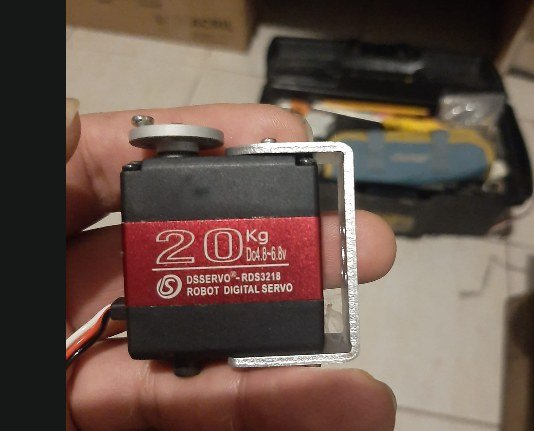

<div align="center"><b>Figura 3.</b> Servo RDS3218 de 20 kg·cm usado en la pinza (apertura y giro J4).</div>

### 1.5 Resumen de actuadores

| Cantidad | Actuador | Uso | Driver | Sensor |
|---|---|---|---|---|
| 2 | 42GM-895H, 12 V, 53 rpm, 189:1 | Tracción diferencial | IBT-2 (uno por motor) | Encoder Hall 11 PPR |
| 1 | 36GP-555, 12 V, 160 rpm, 50:1 | J1 (giro del brazo) | IBT-2 | Encoder SCX-555 16 PPR + final de carrera |
| 2 | 36-555, 12 V, 58 rpm, 139:1 | J2 (hombro) y J3 (codo) | IBT-2 (uno por motor) | Encoder SCX-555 16 PPR + final de carrera |
| 2 | Servo RDS3218, 20 kg·cm | Apertura de la pinza y giro J4 | PWM directo del ESP32 (6 V del buck 3) | Interno del servo |

## Etapa 2: Montaje en el prototipo

### 2.1 Tracción

Los motores de tracción van atrás, en la parte angosta de la base en T, con las ruedas en los rebajes laterales (Entrega 3). Los dos IBT-2 de la tracción y los tres del brazo están atornillados en la cara interna de la caja.

<div align="center">
  <a href="https://lh3.googleusercontent.com/d/1QzPswBik59VWy94oC5ynOpxibmoK4NVv" target="_blank">
    <img src="https://lh3.googleusercontent.com/d/1QzPswBik59VWy94oC5ynOpxibmoK4NVv" width="500">
    <br>
    </a><b>Figura 4.</b> Soporte del motor de tracción fijado a la base (Entrega 3).
</div>

<div align="center">
  <a href="https://lh3.googleusercontent.com/d/1iqb4MU-GAXMCoNLq0LYKrPpkdXIrV3lr" target="_blank">
    <img src="https://lh3.googleusercontent.com/d/1iqb4MU-GAXMCoNLq0LYKrPpkdXIrV3lr" width="500">
    <br>
    </a><b>Figura 5.</b> Motores, drivers y buck fijados a la base (Entrega 3).
</div>

<div align="center">
  <a href="https://lh3.googleusercontent.com/d/1G-BwXYNj3D2_HpSrBouFGbxQegeH8CA-" target="_blank">
    <img src="https://lh3.googleusercontent.com/d/1G-BwXYNj3D2_HpSrBouFGbxQegeH8CA-" width="500" style="transform: rotate(90deg);">
    <br>
    </a><b>Figura 6.</b> Los tres IBT-2 del brazo, uno por articulación.
</div>

### 2.2 Brazo

El brazo va montado atrás a la izquierda, sobre el eje de tracción, en la base impresa en 3D. J1 gira todo el brazo con una correa 18 → 90. Los motores de J2 y J3 quedan en la base del brazo y mueven el hombro y el codo con correas GT2 5:1; el codo se transmite por el cuatro barras.

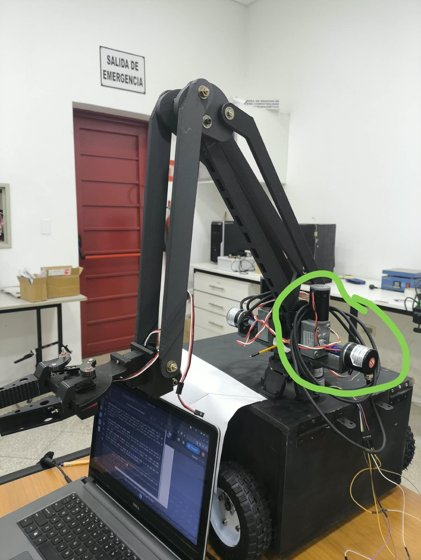

<div align="center"><b>Figura 7.</b> Motor de J2 (hombro) en la base del brazo (marcado en verde).</div>

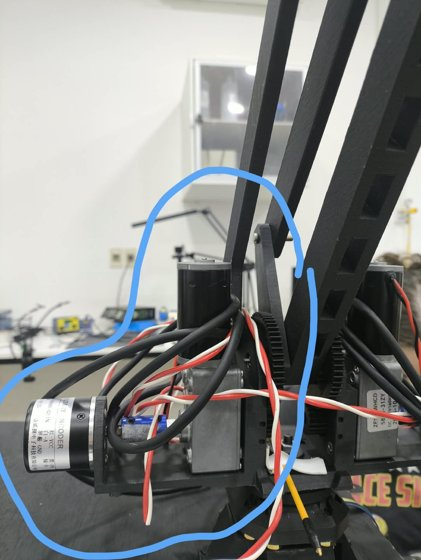

<div align="center"><b>Figura 8.</b> Motor de J3 y su cableado (marcado en azul).</div>

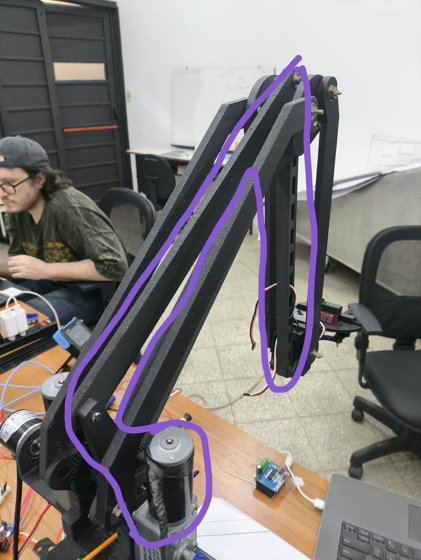

<div align="center"><b>Figura 9.</b> Transmisión del codo (J3) por el cuatro barras (marcado en violeta).</div>

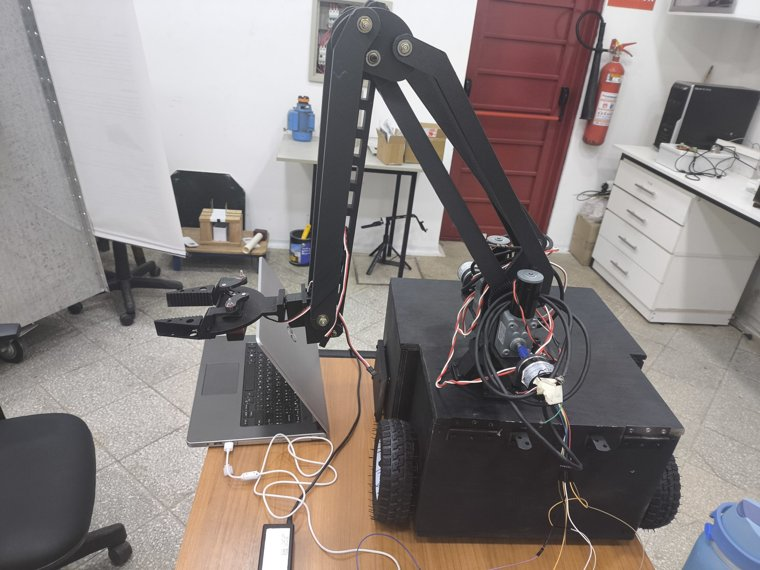

<div align="center"><b>Figura 10.</b> Brazo montado sobre la base, en la posición de cero de J1 (hacia el costado izquierdo), durante la prueba de lazo cerrado de J1.</div>

## Etapa 3: Control de los actuadores

### 3.1 Arquitectura

La Raspberry Pi 5 corre ROS 2 y solo manda consignas por USB (micro-ROS). Cada ESP32 cierra sus lazos cada 10 ms y se detiene solo si pierde la comunicación: la ESP32-S3 maneja la base y su seguridad, y la ESP32-WROOM el brazo. Cada sesión arranca **desarmada**: hay que mandar `armar` por `/<parte>/comando`, para que un nodo que quedó publicando no mueva el robot al reconectar.

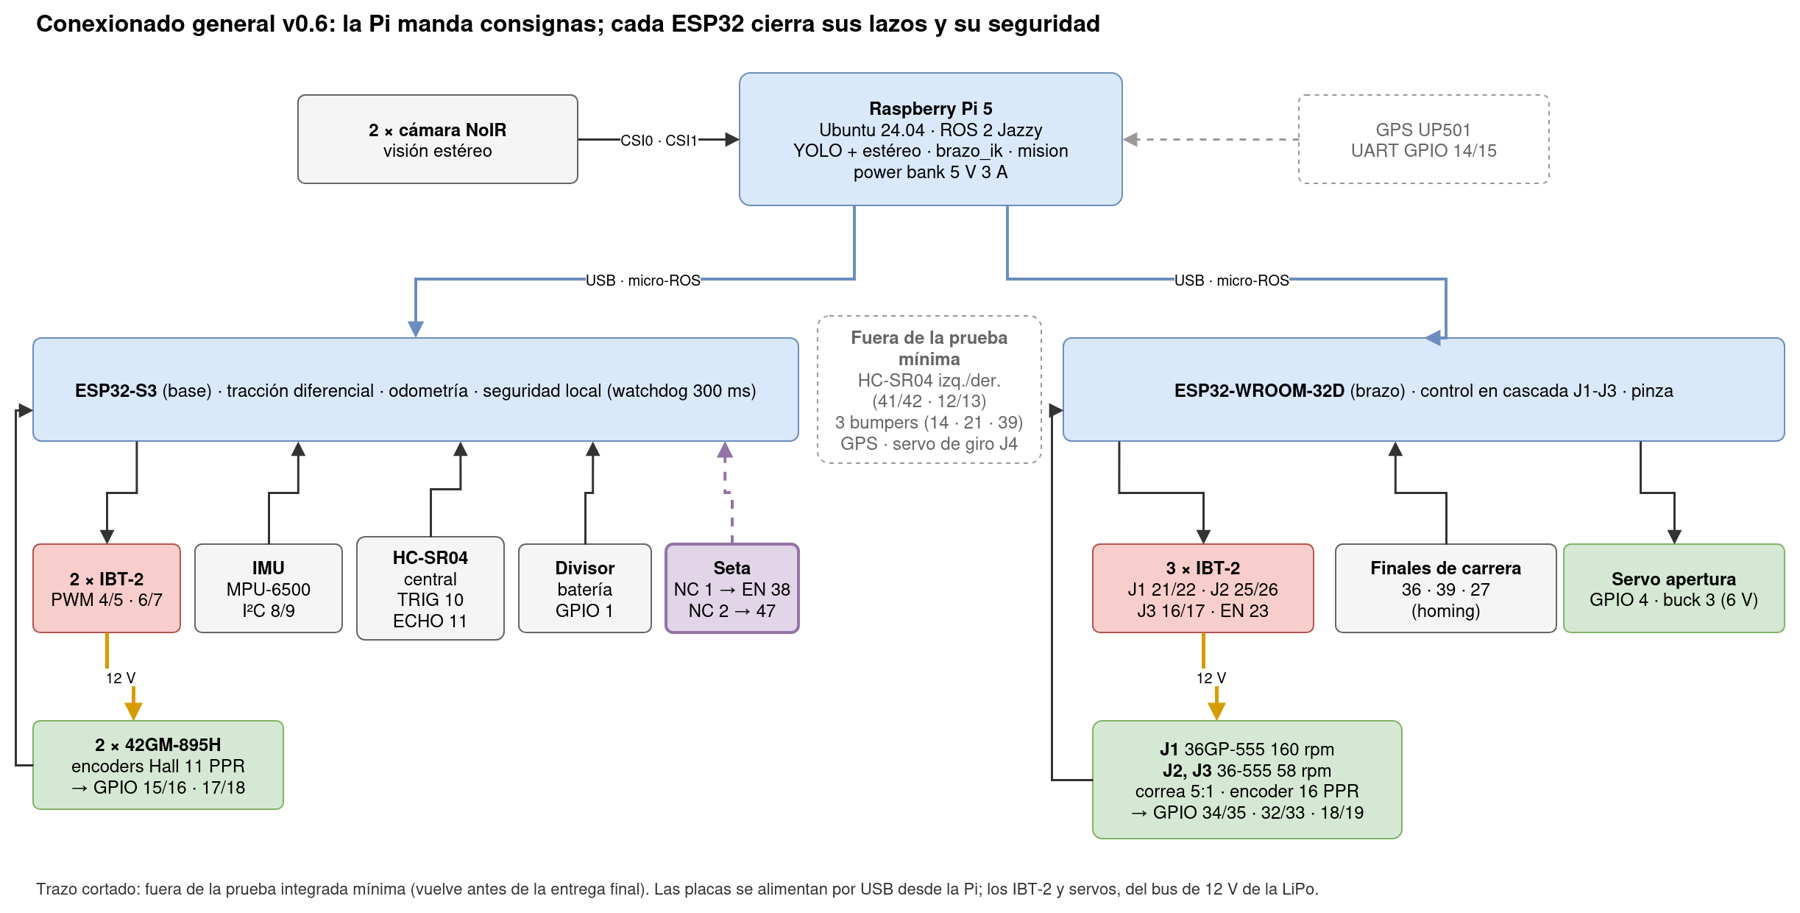

<div align="center"><b>Figura 11.</b> Conexionado general v0.6, con los GPIO de cada placa. En trazo cortado, lo que queda fuera de la prueba integrada mínima.</div>

### 3.2 Control en cascada de las articulaciones

Cada articulación usa dos lazos: el externo de **posición** (P, en grados de la articulación, con límites de velocidad y aceleración) entrega una referencia de velocidad al interno de **velocidad** (PI en rpm del eje del motor, más un *feedforward* de la zona muerta), que calcula el duty del IBT-2 (PWM de 20 kHz). El lazo interno trabaja donde se identificó el modelo $G(s) = K/(\tau s + 1)$ en la Entrega 5 de Robótica I. Los encoders se leen con el contador de pulsos por hardware (PCNT) del ESP32. Al encender, cada articulación hace *homing* contra su final de carrera; sin cero, el firmware rechaza los movimientos.

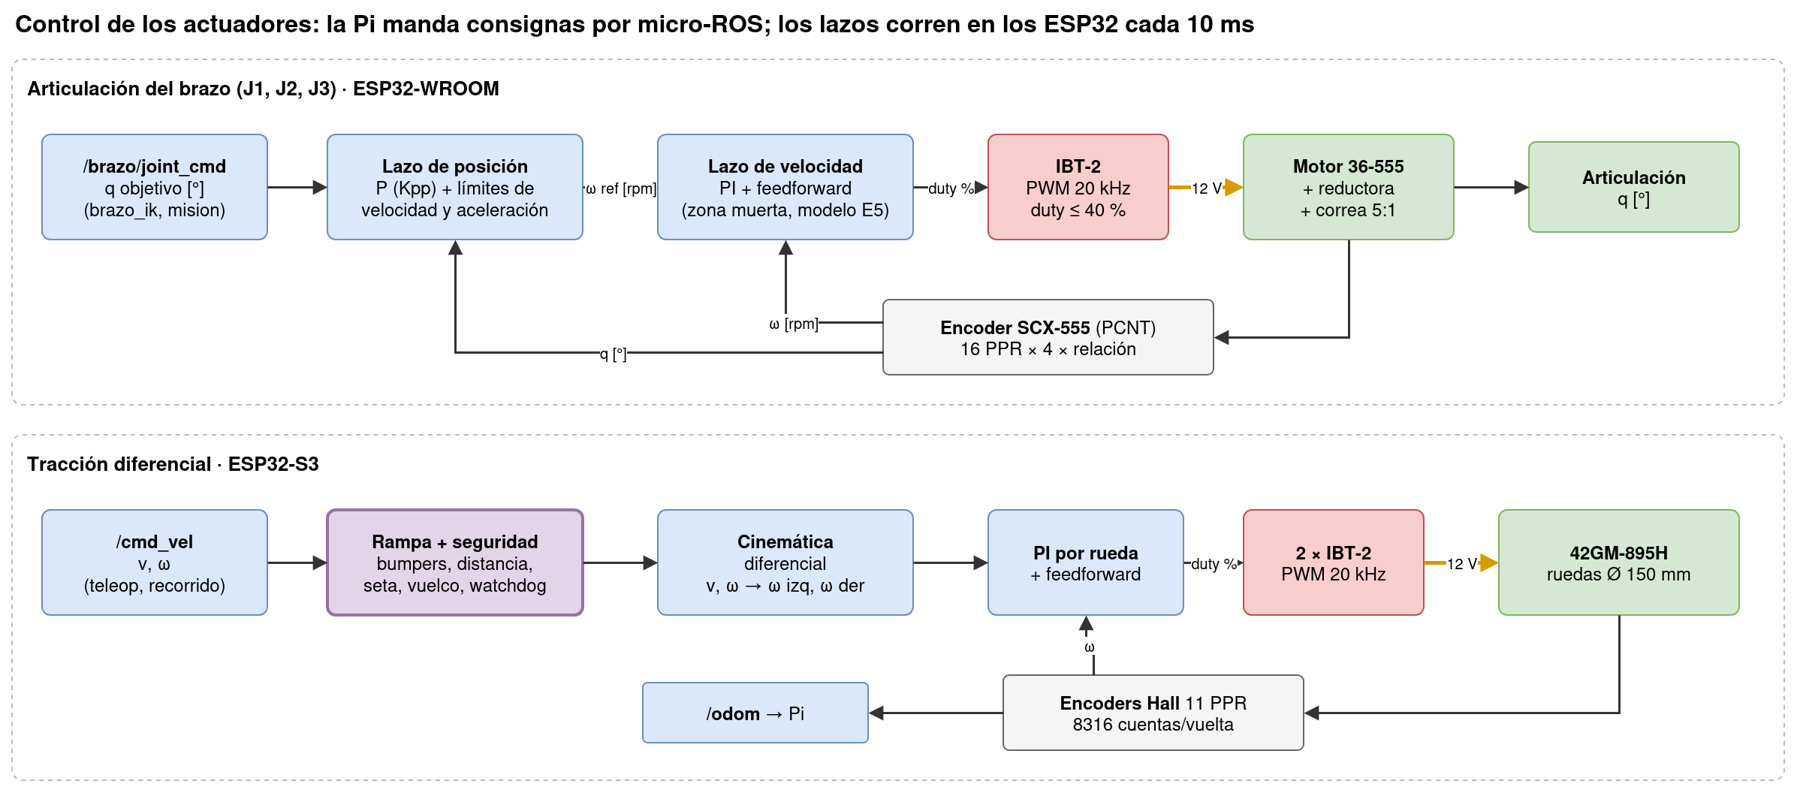

<div align="center"><b>Figura 12.</b> Lazos de control de una articulación del brazo (arriba) y de la tracción diferencial (abajo).</div>

| Parámetro de J1 (medido en el banco) | Valor |
|---|---|
| Zona muerta | 17 % de duty |
| PI de velocidad | 0,659 %/rpm y 4,8 %/(rpm·s) |
| P de posición | 2 (°/s)/° |
| Velocidad y aceleración máximas | 30 °/s y 60 °/s² |
| Tolerancia de llegada | 0,3° |
| Duty máximo | 40 % |

J2 y J3 arrancan con los parámetros de J1 escalados a 58 rpm y se van a ajustar con el mismo procedimiento cuando estén instalados. Los servos de la pinza se manejan con PWM de 50 Hz desde la WROOM.

### 3.3 Control de la tracción

La S3 recibe `/cmd_vel` (velocidad lineal y angular), aplica una rampa y los filtros de seguridad (bumpers, distancia al frente, seta, vuelco con la IMU y watchdog de comandos de 300 ms), convierte a velocidad de cada rueda con la cinemática diferencial y cierra un PI por rueda. Con los encoders publica `/odom` para la Pi.

## Etapa 4: Baterías y cálculo de autonomía

### 4.1 Consumo por subsistema

Los consumos salen de las hojas de los motores (42GM-895H: 2,6 A en vacío, 5,5 A nominal y 10 A trabado; 36-555: 0,5 / 1,3 / 10 A, a 12 V) y de consumos típicos de la Raspberry Pi 5 [1]. Son estimaciones que se van a confirmar con una pinza amperométrica.

| Carga | Potencia | Cómo se estimó |
|---|---|---|
| Tracción avanzando a 0,25 m/s | ~43 W | 2 motores × 60 % de PWM × 12 V × 3 A: la reductora 189:1 pierde mucho incluso en vacío |
| Tracción girando o en terreno malo | ~70 W | más corriente en las dos ruedas |
| Brazo moviéndose (J1-J3 + servos) | ~26 W | J1, J2 y J3 a ~1,3 A en parte del recorrido, más los servos |
| Brazo quieto sosteniendo | ~6 W | J2 y J3 hacen fuerza contra el peso (no se autobloquean) |
| Lógica: Pi 5 con YOLO (~9 W), dos ESP32 (0,8 W), sensores (0,6 W) | ~11 W | picos de ~13 W |

### 4.2 Ciclo de cosecha

Por cada limón (60 s): 20 s avanzando, 5 s maniobrando, 25 s con el brazo en movimiento y 10 s con el brazo quieto, detectando. Mientras la base se mueve, el brazo sostiene su peso. Potencia media en el bus de motores:

$$\bar P = \frac{20\,(43 + 6) + 5\,(70 + 6) + 25 \cdot 26 + 10 \cdot 6}{60} \approx 34{,}5\ \text{W}$$

La energía útil se toma como el 80 % de la nominal, para no descargar del todo las baterías de litio (una descarga profunda acorta su vida [4]), y la autonomía es $t = E_{útil} / \bar P$.

### 4.3 Alternativas evaluadas y corrección del diseño

| Opción | Motores | Lógica (Pi y ESP32) | Autonomía de cosecha | Observaciones |
|---|---|---|---|---|
| A | 10S Li-ion 36 V, 158 Wh, con BMS → buck 36 → 12 V | LiPo 3S → buck 5 V | ~3,2 h | Hacen falta un buck de alta corriente y protección del frenado (Schottky, TVS); 42 V en el robot |
| **B (elegida)** | **LiPo 3S 11,1 V, 88,8 Wh, directa al bus de 12 V** | **Power bank Xiaomi 5 V 3 A** | **~2,1 h** | Sin buck: menos circuito; el frenado vuelve a la batería; todo el robot en ≤ 12,6 V |

Se eligió la opción B: con 2,1 h supera con margen los 45 min que pide la guía (H7) y se arma con componentes que el grupo ya tiene, más un fusible de auto de bajo costo. La 10S queda guardada por si hace falta más autonomía. Con dos fuentes separadas, un motor trabado no puede hacer caer la tensión de la Raspberry Pi.

| Batería | Energía útil | Consumo | Autonomía |
|---|---|---|---|
| LiPo 3S: motores, ciclo de cosecha | 71 Wh | 34,5 W | **~2,1 h** |
| LiPo 3S: motores, avanzando sin parar | 71 Wh | ~48 W | ~1,5 h |
| LiPo 3S: motores, terreno malo sin parar | 71 Wh | ~73 W | ~1 h |
| Power bank: lógica | ~55 Wh (74 Wh × ~75 % a 5 V) | 11 W | **~5 h** |

El robot dura lo que dura la LiPo: **~2,1 h de cosecha**.

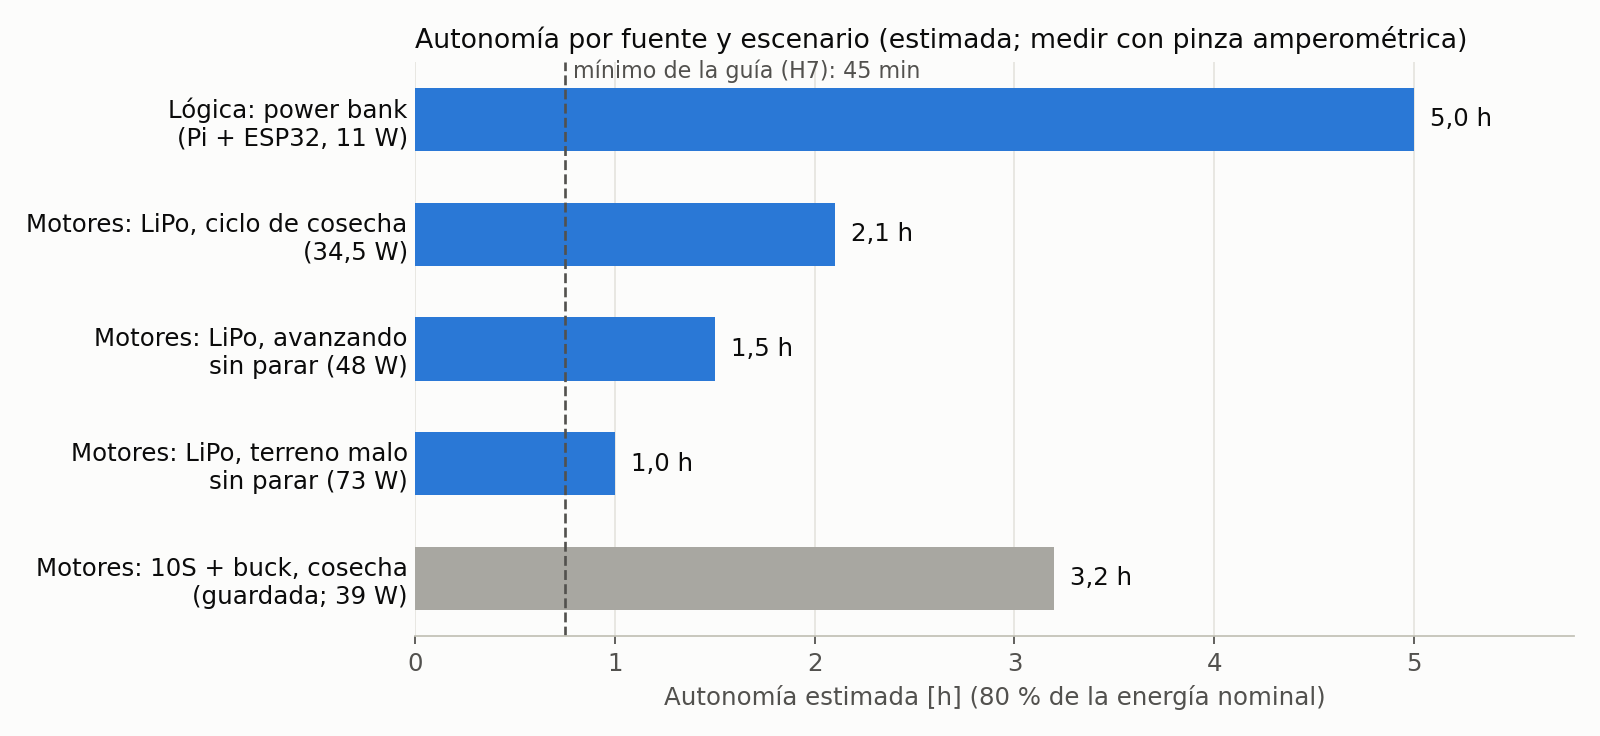

<div align="center"><b>Figura 13.</b> Autonomía estimada por fuente y escenario, frente al mínimo de 45 minutos de la guía.</div>

### 4.4 Baterías seleccionadas

**Motores: LiPo Zeee 3S1P.** 11,1 V nominales (9,9-12,6 V), 8000 mAh, 88,8 Wh, descarga de 100C, conector Deans (T) y balanceo JST-XH; 138 × 47 × 36 mm y 493 g. Los motores son de 12 V y el IBT-2 acepta de 5,5 a 27 V, así que la LiPo va directa al bus de motores. La velocidad sigue a la tensión (−17 % entre 12,6 y 10,5 V), pero el lazo de velocidad lo compensa. No tiene BMS: se carga fuera del robot con un cargador balanceador.

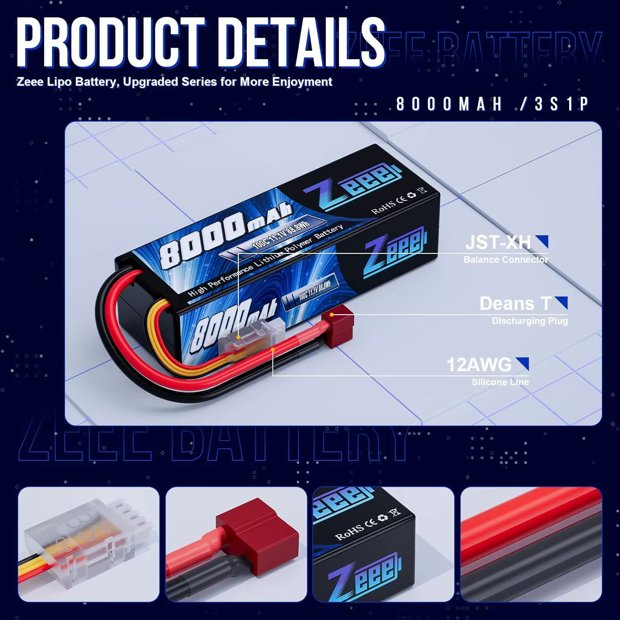

<div align="center"><b>Figura 14.</b> LiPo Zeee 3S de 8000 mAh (motores).</div>

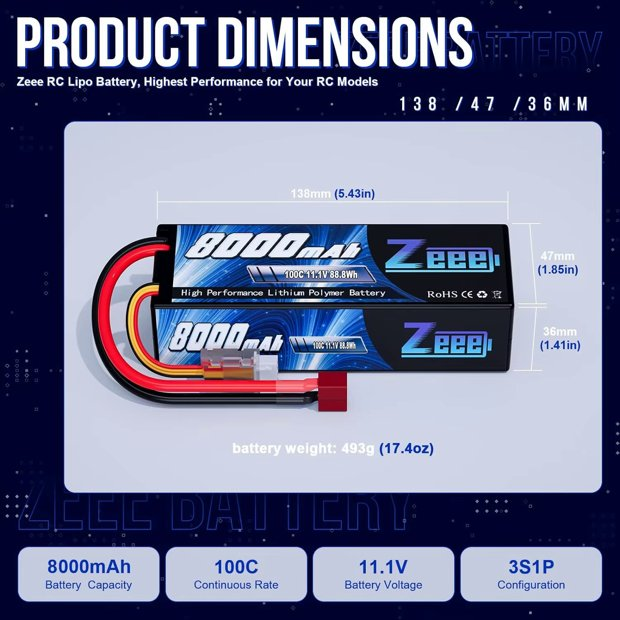

<div align="center"><b>Figura 15.</b> Dimensiones de la LiPo: 138 × 47 × 36 mm, 493 g.</div>

**Lógica: power bank Xiaomi PB2030MI.** 20000 mAh, 33 W, salida de 5 V 3 A por cable USB-C incorporado, con protecciones de cortocircuito, sobrecorriente, sobredescarga y temperatura. Alimenta la Pi 5, y la Pi a los dos ESP32 por USB. La Pi 5 pide 5 V 5 A para dar 1,6 A a sus USB; con 5 V 3 A funciona igual, pero limita a 600 mA el total de los USB y del ventilador [1]. Los dos ESP32 con sus sensores consumen ~400 mA, así que entran; se verifica con `vcgencmd get_throttled` = `0x0` con la visión corriendo.

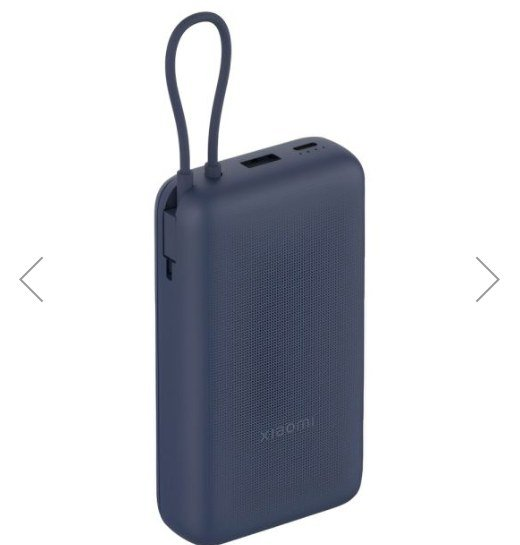

<div align="center"><b>Figura 16.</b> Power bank Xiaomi PB2030MI (Pi 5 y ESP32).</div>

### 4.5 Circuito de potencia y protecciones

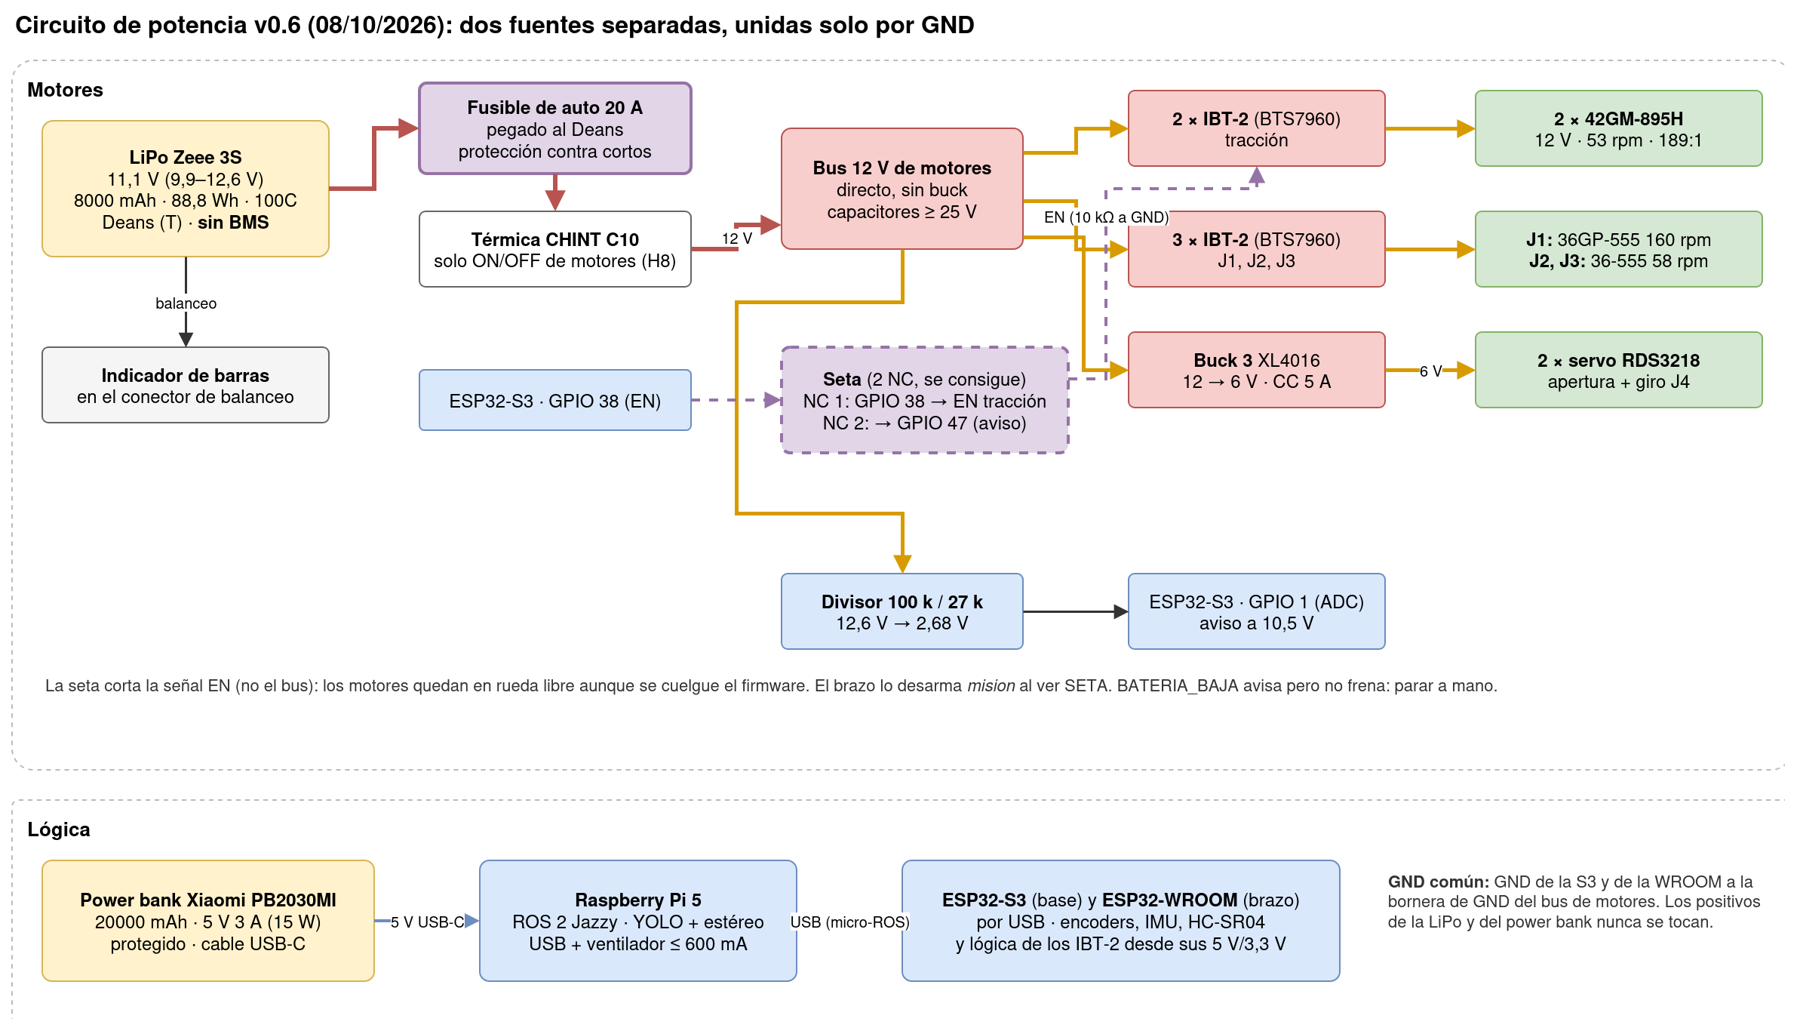

<div align="center"><b>Figura 17.</b> Circuito de potencia v0.6: LiPo directa al bus de 12 V de motores, protegida por un fusible de auto de 20 A, y power bank para la lógica, unidos solo por el GND.</div>

- **Fusible de auto de 20 A**, pegado al conector Deans de la LiPo: es la protección contra un cortocircuito, la falla más peligrosa de una LiPo de 100C sin BMS. Los fusibles de auto son para corriente continua hasta 32 V, así que a 12,6 V trabajan dentro de su especificación; 20 A deja pasar el uso normal (~3 A de promedio, picos de ~15 A) y corta con un corto o con dos motores trabados.
- **Térmica CHINT NXB-63 C10**, después del fusible: es solo el botón ON/OFF de los motores (H8). Está certificada para 230 V de alterna y el fabricante no publica capacidad de corte en continua, por eso no se usa como protección y se acciona con los motores quietos.
- **Seta de emergencia** con dos contactos NC: uno corta la señal EN de los IBT-2 de tracción (los motores quedan en rueda libre aunque se cuelgue el firmware) y el otro avisa a la S3. El contacto de una seta no aguanta la corriente de los motores; por eso corta la señal y no la potencia. El brazo lo desarma el nodo `mision` al recibir el aviso.
- **Buck 3 (XL4016)**: baja los 12 V a 6 V para los servos de la pinza, con límite de corriente de 5 A.
- **Capacitores de ≥ 25 V** en el bus de 12 V, cerca de los IBT-2.
- **GND común**: el GND de cada ESP32 va a la bornera de GND del bus de motores; los positivos de las dos fuentes nunca se unen.

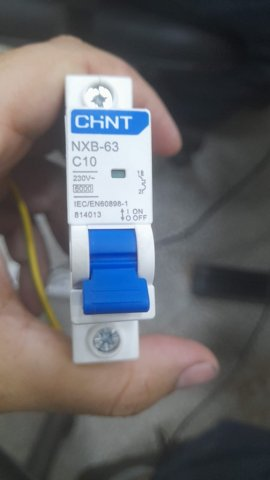

<div align="center"><b>Figura 18.</b> Térmica CHINT NXB-63 C10: interruptor ON/OFF de los motores (la protección es el fusible).</div>

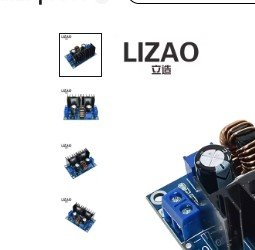

<div align="center"><b>Figura 19.</b> Buck XL4016 (buck 3): 12 → 6 V para los servos.</div>

### 4.6 Nivel de batería y carga (H7)

La guía pide indicar el nivel de batería y disponer de un puerto de carga:

- **Nivel de la LiPo:** un divisor de 100 kΩ / 27 kΩ lleva la tensión (12,6 V → 2,68 V) al ADC de la ESP32-S3, que la publica en ROS y avisa `BATERIA_BAJA` a 10,5 V (3,5 V por celda). Además, un **indicador de barras** en el conector de balanceo la muestra en el robot. Como no hay supervisión por celda, cada celda se mide con el balanceador antes y después de cada prueba.
- **Nivel del power bank:** sus propios LEDs.
- **Carga:** la LiPo se desenchufa por su conector Deans y se carga con el balanceador por el conector JST-XH; el power bank se carga por USB-C.

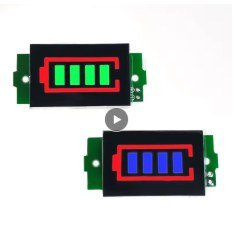

<div align="center"><b>Figura 20.</b> Indicador de barras para baterías de litio de 1S a 8S, en el balanceo de la LiPo.</div>

### 4.7 Ubicación de las baterías en el robot

La LiPo (138 × 47 × 36 mm, 493 g) va dentro de la caja, en el lugar que ocupaba la batería de la Entrega 3, cerca del eje de tracción y lejos de los bordes. El fusible queda pegado a su conector y la térmica, accesible desde la tapa. El power bank va arriba del mástil, al lado de la Raspberry Pi, con su cable USB-C corto: con 3 A, un cable de 5 V largo pierde demasiada tensión.

## Etapa 5: Participación y evidencias

| Integrante | Tareas en esta entrega |
|---|---|
| Pablo Junior Otazu Lujan | PENDIENTE |
| Pedro Daniel Vera Ramírez | PENDIENTE |
| Héctor Dejesús Velázquez Ojeda | PENDIENTE |
| Mathias Ramón Aguilar Delvalle | PENDIENTE |

**Video demo:** PENDIENTE (enlace).

**Carpeta de trabajo «Entrega 4»:** PENDIENTE (enlace a la carpeta compartida con el docente).

Los diagramas de este cuaderno están hechos en draw.io y se pueden editar: `Diagramas/potencia_v06.drawio`, `Diagramas/conexionado_general.drawio` y `Diagramas/control_actuadores.drawio`.

## Referencias

[1] Raspberry Pi Ltd., «Raspberry Pi hardware: Raspberry Pi 5, power supply», documentación oficial. [raspberrypi.com/documentation/computers/raspberry-pi.html](https://www.raspberrypi.com/documentation/computers/raspberry-pi.html). Citada en 4.1 y 4.4 (5 V 3 A con límite de 600 mA para USB y ventilador).

[2] Infineon Technologies, «BTS7960 High Current PN Half Bridge NovalithIC», hoja de datos, rev. 1.1, 2004. [infineon-bts7960-ds-en.pdf](https://www.infineon.com/assets/row/public/documents/10/57/infineon-bts7960-ds-en.pdf). Citada en 1.1.

[3] X. Xiao, Y. Wang y Y. Jiang, «End-Effectors Developed for Citrus and Other Spherical Crops», *Applied Sciences*, vol. 12, n.º 15, art. 7945, 2022 (acceso abierto). [mdpi.com/2076-3417/12/15/7945](https://www.mdpi.com/2076-3417/12/15/7945). Citada en 1.4.

[4] Battery University, «BU-808: How to Prolong Lithium-based Batteries». [batteryuniversity.com/article/bu-808-how-to-prolong-lithium-based-batteries](https://batteryuniversity.com/article/bu-808-how-to-prolong-lithium-based-batteries). Citada en 4.2.

---